# Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

print("Welcome to Student Performance Analytics System")
print("Libraries imported successfully!")

Welcome to Student Performance Analytics System
Libraries imported successfully!


# Create sample student data

In [10]:
data = {
    "Student_ID": [101, 102, 103, 104, 105, 106, 107, 108],
    "Student_Name": ["Asha", "Bala", "Chitra", "Dev","Esha", "Farhan", "Gita", "Hari"],
    "Python": [85, 45, 78, 32, 90, 55, 67, 40],
    "DBMS": [80, 50, 82, 35, 88, 60, 70, 42],
    "DSA": [88, 42, 75, 30, 92, 58, 65, 38],
    "Attendance": [95, 70, 92, 60, 98, 80, 85, 65]
}

df = pd.DataFrame(data)
print('Without using display function\n\n',df,'\n\nUsing display function\n')

display(df)

Without using display function

    Student_ID Student_Name  Python  DBMS  DSA  Attendance
0         101         Asha      85    80   88          95
1         102         Bala      45    50   42          70
2         103       Chitra      78    82   75          92
3         104          Dev      32    35   30          60
4         105         Esha      90    88   92          98
5         106       Farhan      55    60   58          80
6         107         Gita      67    70   65          85
7         108         Hari      40    42   38          65 

Using display function



,Student_ID,Student_Name,Python,DBMS,DSA,Attendance
0,101,Asha,85,80,88,95
1,102,Bala,45,50,42,70
2,103,Chitra,78,82,75,92
3,104,Dev,32,35,30,60
4,105,Esha,90,88,92,98
5,106,Farhan,55,60,58,80
6,107,Gita,67,70,65,85
7,108,Hari,40,42,38,65


# Check and clean the data

In [6]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

df = df.drop_duplicates()

subjects = ["Python", "DBMS", "DSA"]
numeric_columns = subjects + ["Attendance"]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df = df.dropna(subset=numeric_columns)

valid_rows = (
    df[subjects].ge(0).all(axis=1)
    & df[subjects].le(100).all(axis=1)
    & df["Attendance"].between(0, 100)
)

df = df[valid_rows].copy()

print("\nCleaned dataset:")
display(df)

Dataset shape: (8, 6)

Missing values:
Student_ID      0
Student_Name    0
Python          0
DBMS            0
DSA             0
Attendance      0
dtype: int64

Duplicate records: 0

Cleaned dataset:


,Student_ID,Student_Name,Python,DBMS,DSA,Attendance
0,101,Asha,85,80,88,95
1,102,Bala,45,50,42,70
2,103,Chitra,78,82,75,92
3,104,Dev,32,35,30,60
4,105,Esha,90,88,92,98
5,106,Farhan,55,60,58,80
6,107,Gita,67,70,65,85
7,108,Hari,40,42,38,65


# Calculate student averages and results

In [11]:
PASS_MARK = 40

df["Average"] = df[subjects].mean(axis=1).round(2)

df["Result"] = np.where(
    df[subjects].ge(PASS_MARK).all(axis=1),
    "Pass",
    "Needs Improvement"
)

display(df)

,Student_ID,Student_Name,Python,DBMS,DSA,Attendance,Average,Result
0,101,Asha,85,80,88,95,84.33,Pass
1,102,Bala,45,50,42,70,45.67,Pass
2,103,Chitra,78,82,75,92,78.33,Pass
3,104,Dev,32,35,30,60,32.33,Needs Improvement
4,105,Esha,90,88,92,98,90.00,Pass
5,106,Farhan,55,60,58,80,57.67,Pass
6,107,Gita,67,70,65,85,67.33,Pass
7,108,Hari,40,42,38,65,40.00,Needs Improvement


# Calculate subject-wise statistics

In [12]:
subject_summary = df[subjects].agg(
    ["mean", "min", "max"]
).round(2)

subject_summary.index = [
    "Average Marks", "Minimum Marks", "Maximum Marks"
]

display(subject_summary)

,Python,DBMS,DSA
Average Marks,61.5,63.38,61.0
Minimum Marks,32.0,35.00,30.0
Maximum Marks,90.0,88.00,92.0


#  Identify students who may need support

In [13]:
ATTENDANCE_THRESHOLD = 75
AVERAGE_THRESHOLD = 50

df["Support_Reason"] = ""

for index, row in df.iterrows():
    reasons = []

    if row["Attendance"] < ATTENDANCE_THRESHOLD:
        reasons.append("Low attendance")

    if row["Average"] < AVERAGE_THRESHOLD:
        reasons.append("Low average marks")

    if row["Result"] == "Needs Improvement":
        reasons.append("Below pass mark in at least one subject")

    df.at[index, "Support_Reason"] = (
        ", ".join(reasons)
        if reasons else "No flag under current rules"
    )

support_df = df[
    df["Support_Reason"] != "No flag under current rules"
]

display(support_df)

,Student_ID,Student_Name,Python,DBMS,DSA,Attendance,Average,Result,Support_Reason
1,102,Bala,45,50,42,70,45.67,Pass,"Low attendance, Low average marks"
3,104,Dev,32,35,30,60,32.33,Needs Improvement,"Low attendance, Low average marks, Below pass ..."
7,108,Hari,40,42,38,65,40.00,Needs Improvement,"Low attendance, Low average marks, Below pass ..."


#  Calculate overall statistics

In [14]:
total_students = len(df)

pass_count = (df["Result"] == "Pass").sum()

needs_improvement_count = total_students - pass_count

pass_percentage = (
    pass_count / total_students * 100
    if total_students > 0 else 0
)

print("Total students:", total_students)
print("Students passing:", pass_count)
print("Students needing improvement:", needs_improvement_count)
print(f"Pass percentage: {pass_percentage:.2f}%")
print(f"Average attendance: {df['Attendance'].mean():.2f}%")
print(f"Average marks: {df['Average'].mean():.2f}")

Total students: 8
Students passing: 6
Students needing improvement: 2
Pass percentage: 75.00%
Average attendance: 80.62%
Average marks: 61.96


# Visualize subject performance

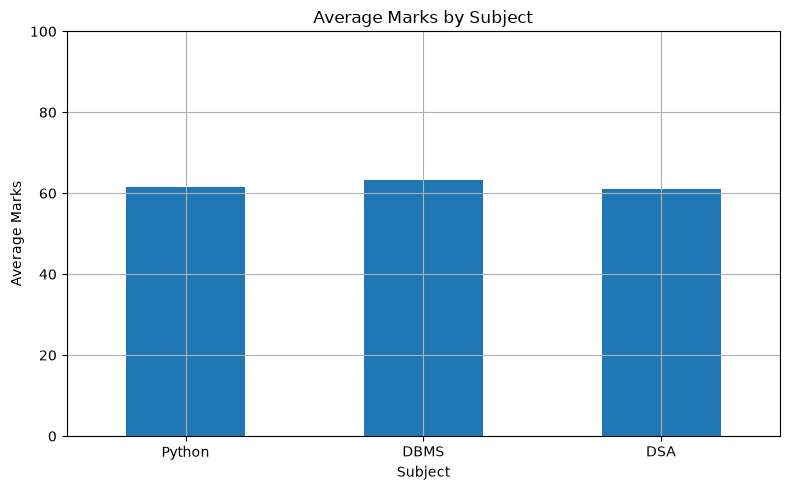

In [17]:
subject_averages = df[subjects].mean()

plt.figure(figsize=(8, 5))
subject_averages.plot(kind="bar")

plt.title("Average Marks by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Marks")
plt.ylim(0, 100)
plt.grid(True)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Visualize attendance versus marks

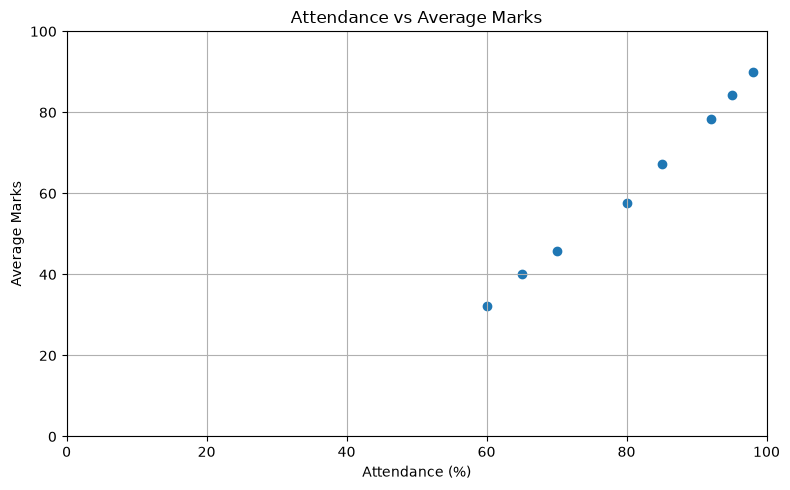

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Attendance"],
    df["Average"]
)

plt.title("Attendance vs Average Marks")
plt.xlabel("Attendance (%)")
plt.ylabel("Average Marks")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.grid(True)
plt.tight_layout()
plt.show()

# Compare pass results

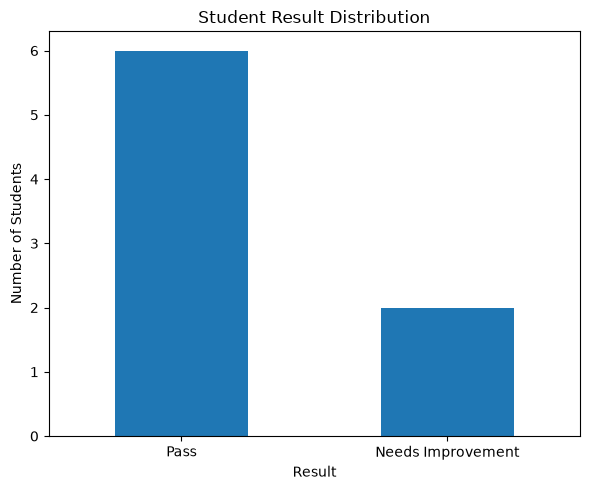

In [18]:
result_counts = df["Result"].value_counts()

plt.figure(figsize=(6, 5))
result_counts.plot(kind="bar")

plt.title("Student Result Distribution")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Export the analysis to CSV

In [19]:
output_columns = [
    "Student_ID", "Student_Name",
    "Python", "DBMS", "DSA",
    "Attendance", "Average",
    "Result", "Support_Reason"
]

df[output_columns].to_csv(
    "student_performance_results.csv",
    index=False
)

print("Results exported to student_performance_results.csv")

Results exported to student_performance_results.csv


# Search for a student

In [20]:
student_name = input("Enter student name: ").strip()

matched_students = df[
    df["Student_Name"].str.casefold()
    == student_name.casefold()
]

if not matched_students.empty:
    display(
        matched_students[
            [
                "Student_Name", "Python", "DBMS", "DSA",
                "Average", "Attendance", "Result",
                "Support_Reason"
            ]
        ]
    )
else:
    print("Student not found.")

Enter student name:  bala


,Student_Name,Python,DBMS,DSA,Average,Attendance,Result,Support_Reason
1,Bala,45,50,42,45.67,70,Pass,"Low attendance, Low average marks"
